# 01. EDA & Preprocessing Verification

## Overview
This notebook verifies the data loading and preprocessing pipeline for the Diabetic Retinopathy Detection project.

## Objectives
1. **Manifest Creation**: Parse `trainLabels.csv` and ensure image files match.
2. **Distribution Analysis**: Visualize the class imbalance (0-4 scales).
3. **Preprocessing Check**: Verify the `crop_black_borders` and resize logic eliminates artifacts without destroying the fundus.
4. **Quality Assessment**: Evaluate image quality using **Vessel Segmentation Density** to identify low-contrast or blurry images.

In [1]:
# 1. Imports & Setup
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Add project root to path
try:
    import src
except ImportError:
    # If running from notebook folder, add parent
    project_root = Path.cwd().parent
    if str(project_root) not in sys.path:
        sys.path.append(str(project_root))

from src.config import load_config, DATA_DIR, PROCESSED_DATA_DIR
from src.data.preprocessing import ImagePreprocessor
from src.data.make_dataset import create_manifest
from src.visualization.plots import set_plot_style, plot_class_distribution, plot_image_grid

# Setup
set_plot_style()
config = load_config()
print("Config Loaded.")
print(f"Data Dir: {DATA_DIR}")

Config Loaded.
Data Dir: C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\data


## 2. Load and Inspect Manifest
We load the labels and create a unified manifest.

In [2]:
manifest_path = PROCESSED_DATA_DIR / "manifest.csv"

# Create or Load Manifest
try:
    if manifest_path.exists():
        print("Loading existing manifest...")
        df = pd.read_csv(manifest_path)
    else:
        print("Creating new manifest...")
        df = create_manifest(DATA_DIR, manifest_path)
except Exception as e:
    # Fallback if logic fails (e.g. files missing) - load csv directly for demo
    print(f"Manifest creation warning: {e}")
    df = pd.read_csv(DATA_DIR / "trainLabels.csv")
    # patch paths for demo
    df['path'] = df['image'].apply(lambda x: str(DATA_DIR / "train" / (x + ".jpeg")))

print(f"Total Samples: {len(df)}")
df.head()

Loading existing manifest...
Total Samples: 35126


,image,level,path,patient_id,eye
0,10_left,0,C:\Users\matteucc\Desktop\Portfolio_improvemen...,10,left
1,10_right,0,C:\Users\matteucc\Desktop\Portfolio_improvemen...,10,right
2,13_left,0,C:\Users\matteucc\Desktop\Portfolio_improvemen...,13,left
3,13_right,0,C:\Users\matteucc\Desktop\Portfolio_improvemen...,13,right
4,15_left,1,C:\Users\matteucc\Desktop\Portfolio_improvemen...,15,left


## 3. Class Distribution
The dataset is known to be heavily imbalanced.

c:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\src\visualization\plots.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=label_col, data=df, palette=colors, ax=ax)


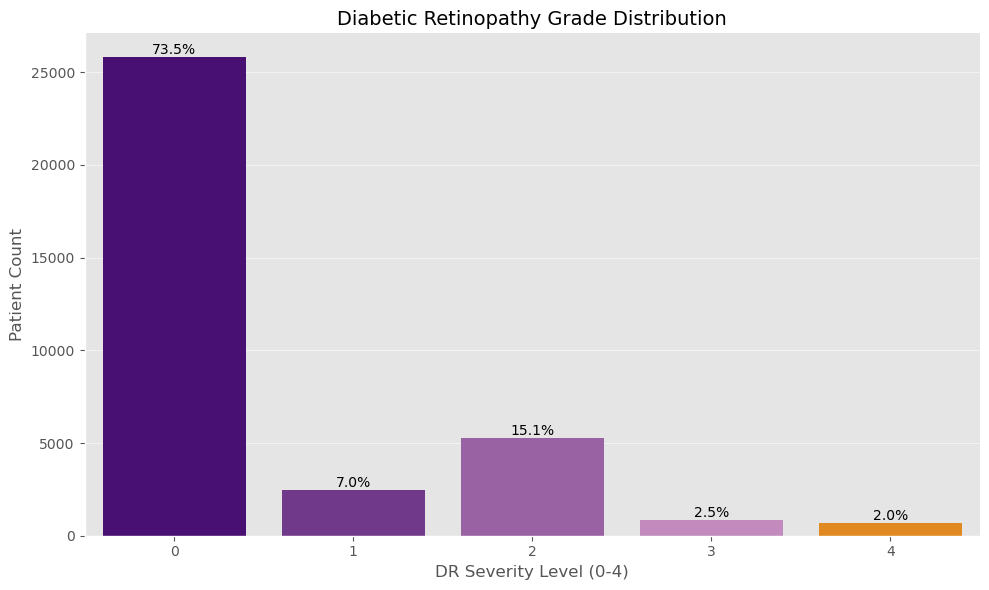

In [3]:
fig = plot_class_distribution(df, label_col='level', title="Diabetic Retinopathy Grade Distribution")
plt.show()

## 4. Preprocessing Verification
We test the `ImagePreprocessor` on a random batch of images.
We want to see the effect of cropping black borders.

Processing 6 random samples...
Displaying Raw Images...


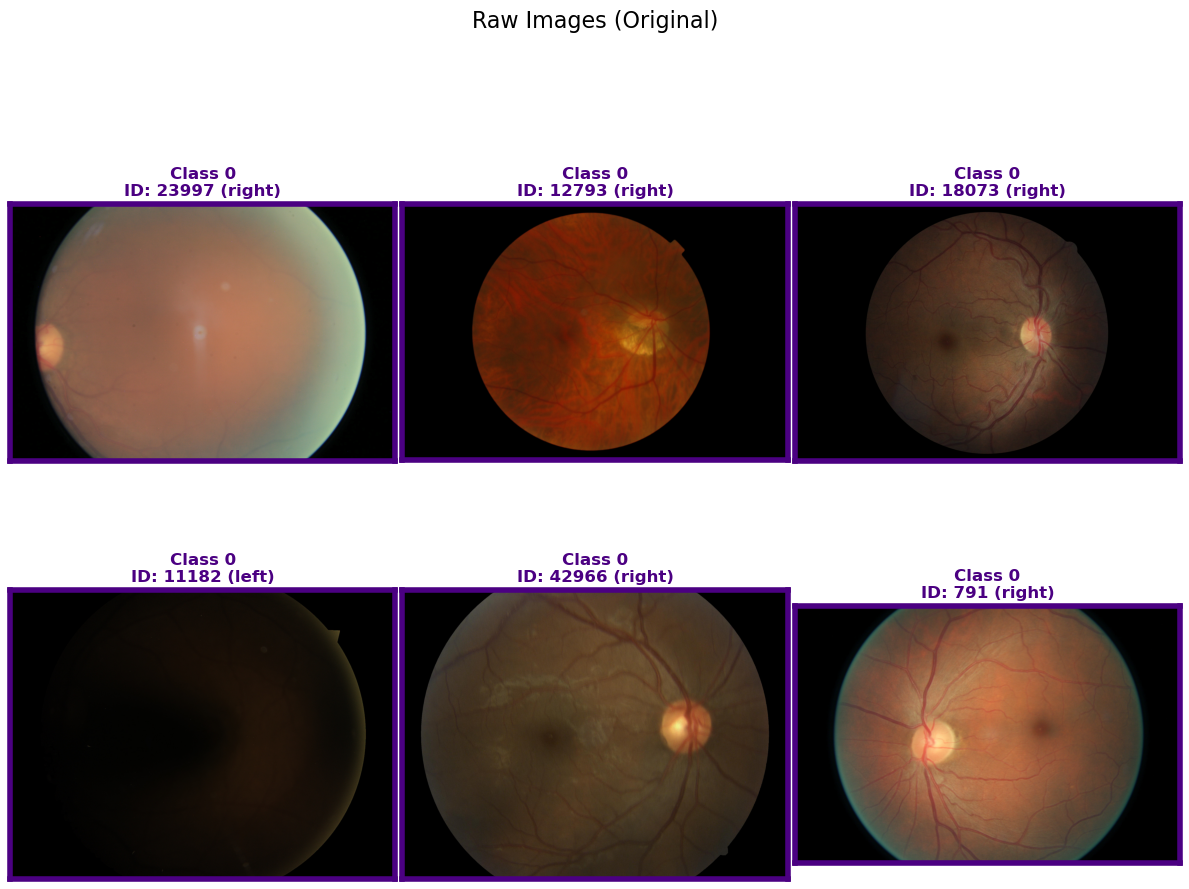

Displaying Processed Images (Graham's Method)...


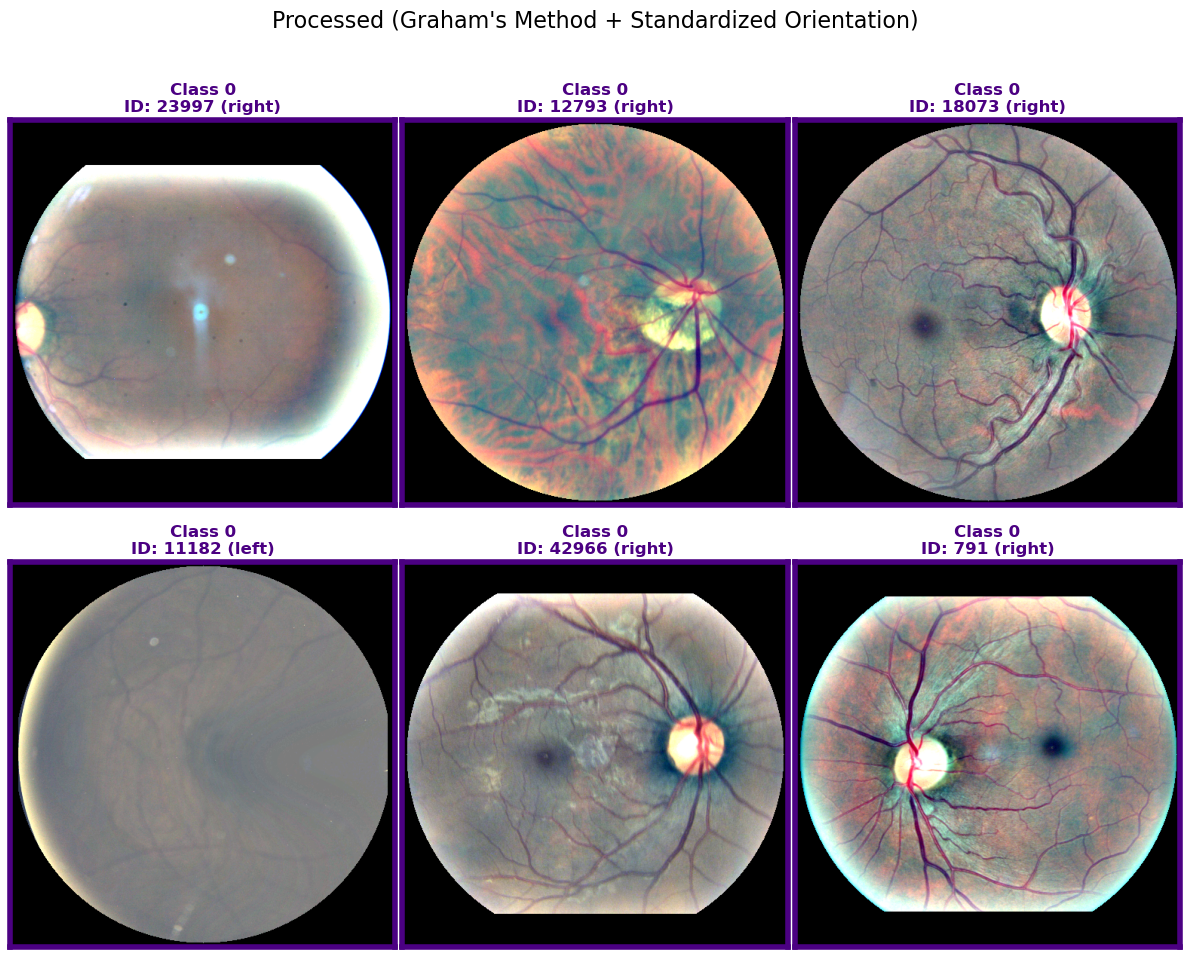

In [4]:
# Initialize the Preprocessor
preprocessor = ImagePreprocessor(target_size=(512, 512), sigmaX=30)

# Select random samples
n_samples = 6
samples = df.sample(n_samples, random_state=42).to_dict('records')

print(f"Processing {n_samples} random samples...")

raw_imgs = []
proc_imgs = []
labels = []
titles = []

for row in samples:
    # 1. Load Raw (Convert BGR to RGB for display)
    img_bgr = cv2.imread(row['path'])
    if img_bgr is not None:
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    else:
        img_rgb = np.zeros((512, 512, 3), dtype=np.uint8)
    
    # 2. Process
    processed = preprocessor.preprocess(img_rgb, eye_side=row['eye'])
    
    # Store
    raw_imgs.append(img_rgb)
    proc_imgs.append(processed)
    labels.append(row['level'])
    
    # Title format: "Class X\nID: Y (left)"
    titles.append(f"Class {row['level']}\nID: {row['patient_id']} ({row['eye']})")

# 1. Plot Raw Images
print("Displaying Raw Images...")
plot_image_grid(
    raw_imgs, 
    labels, 
    titles=titles,
    grid_shape=(2, 3), 
    figsize=(12, 10),
    title="Raw Images (Original)",
    save_folder="eda"
)
plt.show()

# 2. Plot Processed Images
print("Displaying Processed Images (Graham's Method)...")
plot_image_grid(
    proc_imgs, 
    labels, 
    titles=titles,
    grid_shape=(2, 3), 
    figsize=(12, 10),
    title="Processed (Graham's Method + Standardized Orientation)",
    save_folder="eda"
)
plt.show()

### Preprocessing Observations
- **Successes**: The pipeline successfully standardizes retinal scale (zoom) and removes confounding color variations (via Graham's method), effectively highlighting structural patterns like vessels and lesions.
- **Limitations**: The orientation standardization (flipping left eyes to look like right eyes) shows inconsistencies. This appears to be due to inherent mislabeling of eye side in the raw dataset (e.g., a "right" label on a physically "left" image).
  - *Mitigation*: This is a known issue with EyePACS and should not negatively impact the network, as we will use random horizontal flips during training which makes the model invariant to laterality.

## 5. Quality Assessment (QC)
We replace the simple Blur Score with **Vessel Segmentation Density**.
- **Logic**: A high-quality fundus image must have visible, sharp blood vessels.
- **Metric**: Percentage of the retina area covered by detected vessels (Adaptive Thresholding).
- **Visualization**: We overlay the detected vessel map (Red) to confirm the metric aligns with visual reality.

Running Vessel Density Quality Check...

--- Vessel Density Report ---


,ID,Level,Vessel Density
0,23997,0,0.0209
1,12793,0,0.0856
2,18073,0,0.1472
3,11182,0,0.0025
4,42966,0,0.1132
5,791,0,0.1448



Visualizing Vessel Segmentation (Dark Purple Overlay)...


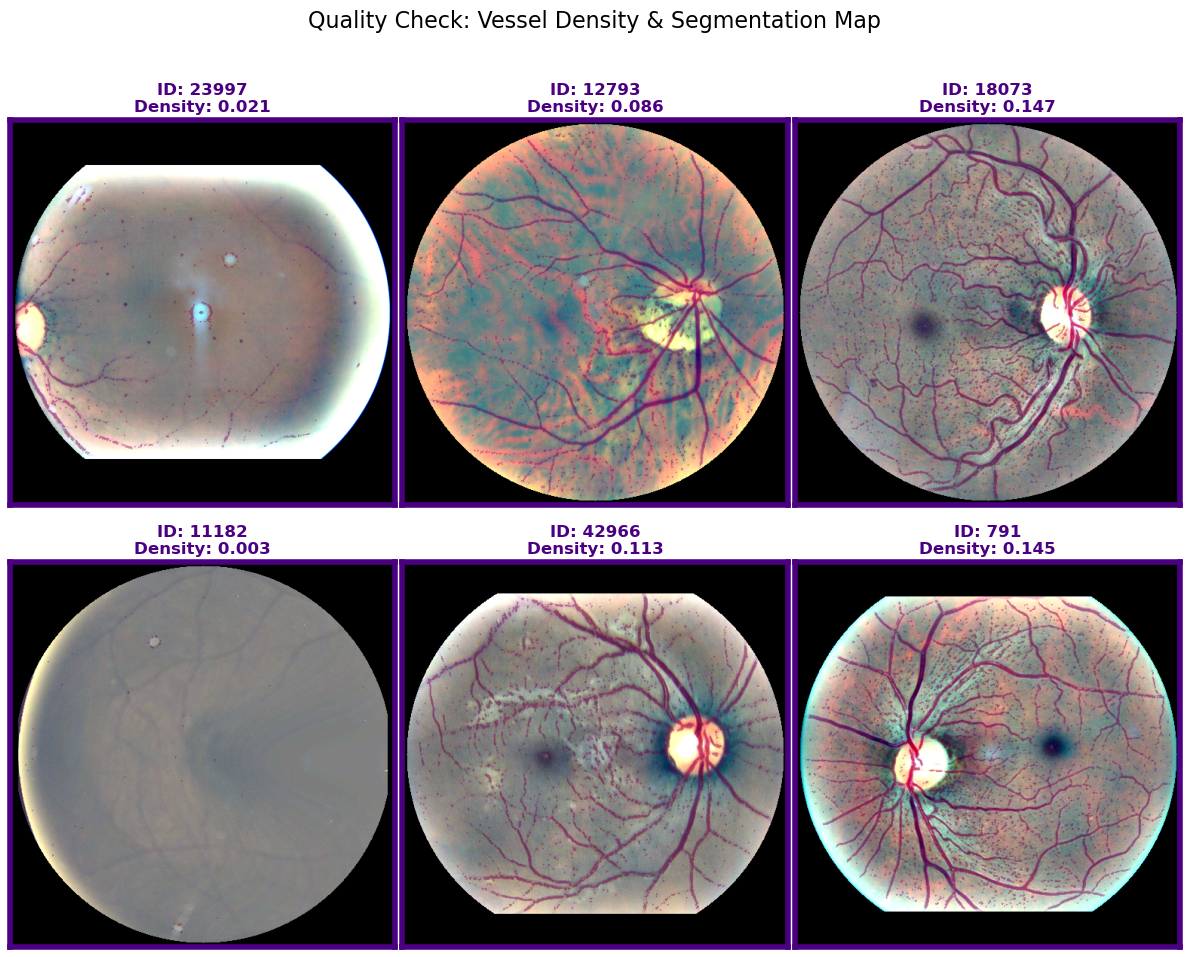

Higher density indicates coherent vessel structure (good focus/contrast).


In [5]:
print("Running Vessel Density Quality Check...")

qc_results = []
qc_images = []
qc_titles = []
qc_labels = []

# Define Deep Purple Overlay Color (BGR format for OpenCV)
# Hex: #4B0082 -> RGB: (75, 0, 130) -> BGR: (130, 0, 75)
PURPLE_BGR = (130, 0, 75)

for i, row in enumerate(samples):
    # Load raw image
    img = preprocessor.load_image(row['path'])
    
    # Process Image (Standard Pipeline)
    proc_img = preprocessor.preprocess(img, eye_side=row['eye'])
    
    # Compute Density on Processed Image (most reliable)
    qc_metrics = preprocessor.validate_quality(proc_img)
    density = qc_metrics['vessel_density']
    
    # Get Mask for Visualization
    mask = preprocessor.extract_vessel_mask(proc_img)
    
    # Create Overlay: Image + Purple Mask
    overlay = proc_img.copy()
    
    # Apply color only where mask is white (vessels)
    # We blend so it looks like a transparent highlighter
    # Indices where mask is non-zero
    y_idxs, x_idxs = np.where(mask > 0)
    
    # Blend manually for control
    # alpha = 0.6 (Image), beta = 0.4 (Color)
    for y, x in zip(y_idxs, x_idxs):
        pixel = overlay[y, x]
        # Linear blend: 0.6*Original + 0.4*Purple
        blended = 0.6 * pixel + 0.4 * np.array(PURPLE_BGR)
        overlay[y, x] = blended.astype(np.uint8)

    qc_results.append({
        "ID": row['patient_id'],
        "Level": row['level'],
        "Vessel Density": density
    })
    
    # Collect for plotting
    qc_images.append(overlay)
    qc_labels.append(row['level'])
    qc_titles.append(f"ID: {row['patient_id']}\nDensity: {density:.3f}")

qc_df = pd.DataFrame(qc_results)
print("\n--- Vessel Density Report ---")
display(qc_df.round(4))

# Visual Verification
print("\nVisualizing Vessel Segmentation (Dark Purple Overlay)...")
if qc_images:
    plot_image_grid(
        qc_images,
        qc_labels,
        titles=qc_titles,
        grid_shape=(2, 3), 
        figsize=(12, 10),
        title="Quality Check: Vessel Density & Segmentation Map",
        save_folder="eda"
    )
    plt.show()

# Interpretation
print("Higher density indicates coherent vessel structure (good focus/contrast).")

## 6. Dataset Class Test
This cell verifies that the PyTorch Dataset correctly uses our Preprocessor.


Verifying Dataset Integration...

--- Dataset Output for Index 0 ---
Tensor Shape: torch.Size([3, 512, 512]) (Channels, Height, Width)
Value Range:  [0.0000, 1.0000]
Data Type:    torch.float32
Label:        0


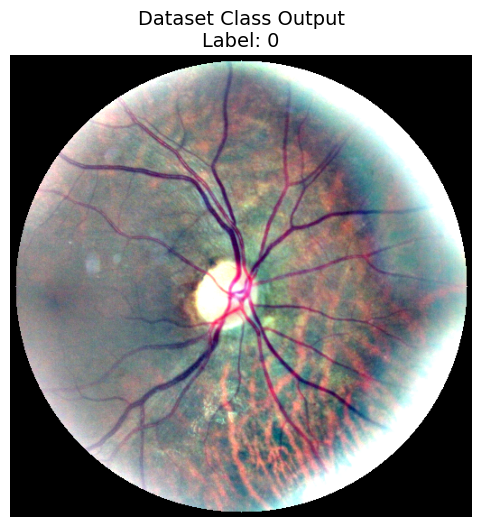

In [6]:
from src.data import ImagePreprocessor, RetinopathyDataset
import torch

print("Verifying Dataset Integration...")

# 1. Initialize Preprocessor (Exact same config as above)
# We recreate it to ensure the dataset works standalone
prod_preprocessor = ImagePreprocessor(target_size=(512, 512), sigmaX=30) 

# 2. Create Dataset Instance
# We reuse the 'df' DataFrame from the start of the notebook
dataset_check = RetinopathyDataset(df=df, preprocessor=prod_preprocessor)

# 3. Retrieve a Single Sample (Simulate what the DataLoader does)
sample_idx = 0  # Pick the first image
data_item = dataset_check[sample_idx]

tensor_img = data_item['image']
label = data_item['label']

print(f"\n--- Dataset Output for Index {sample_idx} ---")
print(f"Tensor Shape: {tensor_img.shape} (Channels, Height, Width)")
print(f"Value Range:  [{tensor_img.min():.4f}, {tensor_img.max():.4f}]")
print(f"Data Type:    {tensor_img.dtype}")
print(f"Label:        {label}")

# 4. Visualize the Tensor
# We need to convert from PyTorch (C,H,W) to Matplotlib (H,W,C)
plt.figure(figsize=(6,6))
plt.imshow(tensor_img.permute(1, 2, 0).numpy())
plt.title(f"Dataset Class Output\nLabel: {label}")
plt.axis('off')
plt.show()

## 7. Data Augmentation Verification
We verify the **Albumentations** pipeline. 
Since medical images can be rotated freely (the retina is circular), we apply aggressive geometric transformations (Rotation, Flips) to prevent overfitting.
We also verify that the `RetinopathyDataset` correctly hooks into these transforms.

--- FINAL SYSTEM VERIFICATION ---
Using Class from: c:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\src\data\transforms.py
Visualizing augmentations for Patient: 10


c:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\src\data\transforms.py:26: UserWarning: Argument(s) 'always_apply' are not valid for transform BasicTransform
  super(IsotropicAffineTransform, self).__init__(always_apply=always_apply, p=p)


--- Plotting Verification Grid ---


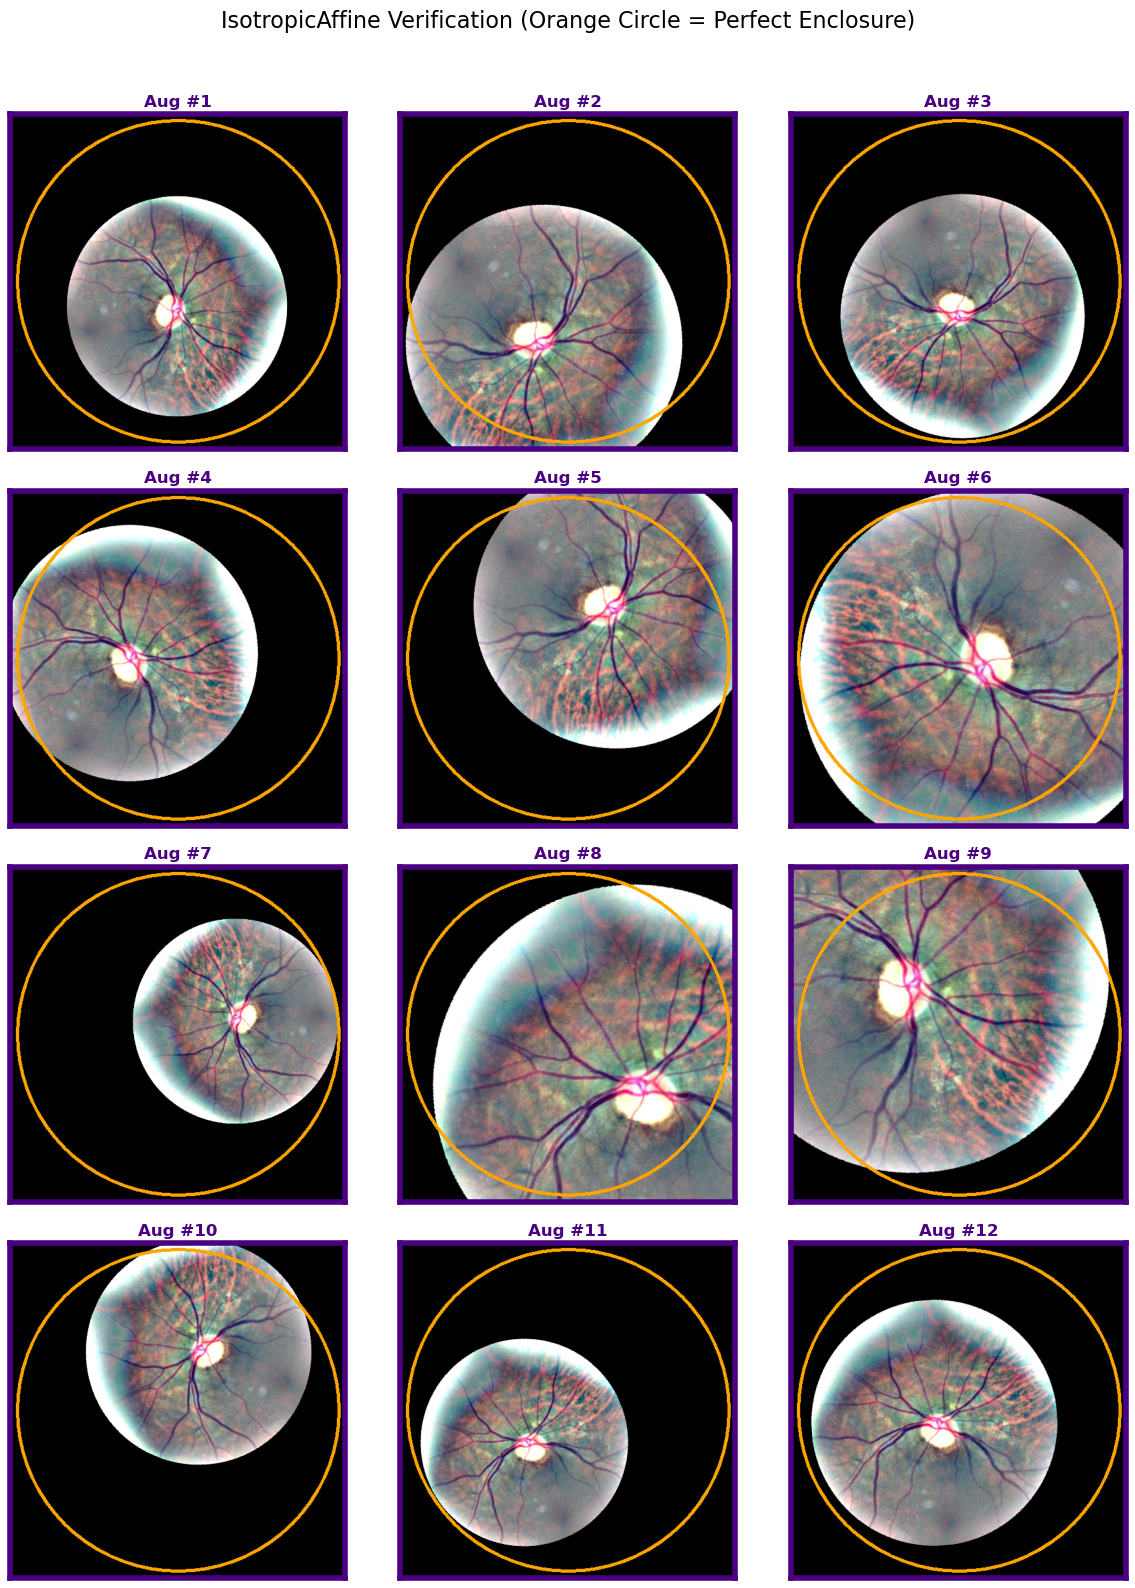

In [ ]:
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
import numpy as np
import importlib

# 1. Reload Transforms to ensure we have the latest production logic
import src.data.transforms
importlib.reload(src.data.transforms)
from src.data.transforms import IsotropicAffineTransform

print("--- Augmentation system verification ---")
print("Using Class from:", src.data.transforms.__file__)

# 2. Define Pipeline using the IMPORTED class
iso_transforms = A.Compose([
    IsotropicAffineTransform(
        scale_limit=0.4,   # +/- 40% (Aggressive for demo)
        shift_limit=0.2,   
        rotate_limit=180,  
        p=1.0 
    ),
    ToTensorV2()
])

# 3. Create Dataset using the Standard Pipeline
iso_dataset = RetinopathyDataset(
    df=df, 
    preprocessor=prod_preprocessor,
    transforms=iso_transforms
)

# 4. Visualize
sample_idx = 0 
sample_row = df.iloc[sample_idx]
print(f"Visualizing augmentations for Patient: {sample_row['patient_id']}")

iso_images = []
iso_titles = []
iso_labels = []

for i in range(12):
    # Retrieve from Dataset (which calls transforms)
    data_item = iso_dataset[sample_idx]
    img_tensor = data_item['image']
    label = data_item['label']
    
    # Convert Tensor -> Numpy for plotting
    display_img = img_tensor.permute(1, 2, 0).numpy()
    
    # Overlay Orange Reference Circle (RGB: 255, 165, 0)
    h, w = display_img.shape[:2]
    debug_img = display_img.copy()
    
    # Ensure uint8 for OpenCV drawing
    if display_img.max() <= 1.0: 
         debug_img = (display_img * 255).astype(np.uint8)
    
    # Draw Circle (Orange)
    cv2.circle(debug_img, (w//2, h//2), int(min(h,w)*0.48), (255, 165, 0), 3)
    
    iso_images.append(debug_img)
    iso_titles.append(f"Aug #{i+1}")
    iso_labels.append(label.item()) 

print("--- Plotting Verification Grid ---")
plot_image_grid(
    iso_images, 
    labels=iso_labels, 
    titles=iso_titles, 
    grid_shape=(4, 3), 
    figsize=(12, 16),   
    title=f"IsotropicAffine Verification (Orange Circle = Perfect Enclosure)",
    save_folder=None
)
plt.show()